### Cache Augumented Generation (CAG)

Cahce the response to improve the performance of the RAG.

CAG is retrieval-free approach thtbypass the usual step of querying external knowldege at inference time. Instead , it preloads relevant documents into the LLM's extended context window, precomputes the model's key-value(KV) cache, and reuses this during inference - so the model can generate responses without additional retrieval steps.

In [ ]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

from langchain.chat_models import init_chat_model
llm = init_chat_model("openai:gpt-4o-mini")

llm

ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3', 'langchain-openai': '1.6.7'}}, profile={'name': 'GPT-4o mini', 'release_date': '2024-07-18', 'last_updated': '2024-07-18', 'open_weights': False, 'max_input_tokens': 128000, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x000002199C3082B0>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x000002199C3089D0>, root_client=<openai.OpenAI object at 0x000002199ADAA520>

In [69]:
### Cache variable
Model_cache = {}

In [70]:
import time

def cache_model(query):
    start_time = time.time()
    if Model_cache.get(query):
        print("**Cache hit**")
        end_time = time.time()
        print(f"Query retrieved from cache in {end_time - start_time} seconds")
        return Model_cache.get(query)
    else:
        print("**Cache miss** Executing Model")
        start_time = time.time()
        response = llm.invoke(query)
        end_time = time.time()
        elapsed = end_time - start_time
        Model_cache[query] = response
        print(f"Query processed in {elapsed} seconds")
        return response

In [59]:
response = cache_model("Hi")
response

**Cache miss** Executing Model


Query processed in 1.624190330505371 seconds


AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 8, 'total_tokens': 17, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_f1b0ec5777', 'id': 'chatcmpl-Eax4qBJMVUtetMeALkAKq5lnwqFB2', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a157df-33e9-7cb2-bb1b-2924c30b594f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 9, 'total_tokens': 17, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

In [60]:
response = cache_model("what are key benefits of caching")
response

**Cache miss** Executing Model
Query processed in 4.047441244125366 seconds


AIMessage(content='Caching is an optimization technique used in computer science and software engineering to store copies of frequently accessed data in a faster storage layer. Here are some key benefits of caching:\n\n1. **Improved Performance**: Caching significantly reduces the time it takes to retrieve data since accessing data from cache is much faster than retrieving it from the primary data source (like a database or a disk).\n\n2. **Reduced Latency**: By serving data from the cache, applications can respond to user requests more quickly, improving the overall user experience, particularly in web applications.\n\n3. **Reduced Load on Back-End Systems**: By offloading repeated requests from back-end services (such as databases, APIs, or file systems), caching lessens the load on these systems, which can lead to improved scalability.\n\n4. **Increased Throughput**: With reduced latency and improved performance, caching helps increase the number of transactions that can be processe

### Advance CAG

    Semantic Cache

In [71]:
from __future__ import annotations
from typing import TypedDict, List, Optional
import time

from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.documents import Document
from langchain_openai import ChatOpenAI, OpenAIEmbeddings

import faiss
from langchain_community.vectorstores import FAISS
from langchain_community.docstore.in_memory import InMemoryDocstore

In [107]:
import truststore
truststore.inject_into_ssl()

In [74]:
# ================== CONFIG =======================
EMBED_MODEL = "text-embedding-3-small"
VECTOR_DIM = 1536

LLM_MODEL = "gpt-4o-mini"
LLM_TEMPERATURE = 0

RETRIEVE_TOP_K = 4
CACHE_TOP_K = 3

In [76]:
CACHE_DISTANCE_THRESHOLD = 0.45

#Optional TTL for cahce entries (seconds). 0 = disabled.
CACHE_TTL_SEC = 0

In [92]:
# ====================== STATE =====================
class RAGState(TypedDict):
    question: str
    normalized_question: str
    context_doc: List[Document]
    answer: Optional[str]
    citations: List[str]
    cache_hit: bool

In [79]:
# ======================== GLOBALS =====================

EMBED = OpenAIEmbeddings(model=EMBED_MODEL)

In [77]:
# ------------ QA CACHE (EMPTY, SAFE INIT) -----
qa_index = faiss.IndexFlatL2(VECTOR_DIM) # distance; lower is better
QA_CACHE = FAISS(
    embedding_function=EMBED,
    index=qa_index,
    docstore = InMemoryDocstore({}),
    index_to_docstore_id={},
)

In [80]:
QA_CACHE

In [81]:
# ---- RAG STORE (demo only) ----
RAG_STORE = FAISS.from_texts(
    texts = [
        "LangGraph lets you compose stateful LLM workflows as graphs. ",
        "In LangGraph, nodes can be cached; node caching memoizes outputs keyed by inputs for a TTL.",
        "Retrieval-Augmented Generation (RAG) retrieves external context and injects it into prompts.",
        "Semantic caching reuses prior answer when new questions are semantically similar."
    ],
    embedding=EMBED,
)

In [82]:
LLM = ChatOpenAI(model=LLM_MODEL, temperature=LLM_TEMPERATURE)

In [84]:
LLM = ChatOpenAI(model=LLM_MODEL, temperature=LLM_TEMPERATURE)


In [113]:
# ======== NODES =============
def normalize_query(state: RAGState) -> RAGState:
    q = (state["question"] or "").strip()
    state["normalized_question"] = q.lower()
    return state

def semantic_cache_lookup(state: RAGState) -> RAGState:
    q = state["normalized_question"]
    state["cache_hit"] = False

    if not q:
        return state

    if getattr(QA_CACHE, "index", None) is None or QA_CACHE.index.ntotal == 0:
        return state

    hits = QA_CACHE.similarity_search_with_score(q, k=CACHE_TOP_K)
    if not hits:
        return state

    best_doc, dist = hits[0]

    if CACHE_TTL_SEC > 0:
        ts = best_doc.metadata.get("ts")
        if ts is None or (time.time() - float(ts)) > CACHE_TTL_SEC:
            return state

    if dist <= CACHE_DISTANCE_THRESHOLD:
        cached_answer = best_doc.metadata.get("answer")
        if cached_answer:
            state["answer"] = cached_answer
            state["citations"] = ["(cache)"]
            state["cache_hit"] = True

    return state

def response_from_cache(state: RAGState) -> RAGState:
    return state

def generate(state: RAGState) -> RAGState:
    q = state["question"]
    docs = state.get("context_docs", [])
    ctx = "\n\n".join(
        f"[doc-{index}] {doc.page_content}"
        for index, doc in enumerate(docs, start=1)
    )

    system = (
        "You are a precise RAG assistant. Use the context when helpful. "
        "Cite with [doc-i] markers if you use a fact from the context."
    )
    user = f"Question: {q}\n\nContext:\n{ctx}\n\nWrite a concise answer with citations."
    resp = LLM.invoke([
        {"role": "system", "content": system},
        {"role": "user", "content": user},
    ])
    state["answer"] = resp.content
    state["citations"] = [f"[doc-{index}]" for index in range(1, len(docs) + 1)]
    return state

def retrieve(state: RAGState) -> RAGState:
    q = state["normalized_question"]
    docs = RAG_STORE.similarity_search(q, k=RETRIEVE_TOP_K)
    state["context_docs"] = docs
    return state

def cache_write(state: RAGState) -> RAGState:
    q = state["normalized_question"]
    answer = state.get("answer")
    if not q or not answer:
        return state

    doc = Document(
        page_content=q,
        metadata={"ts": str(time.time()), "answer": answer},
    )
    QA_CACHE.add_documents([doc])
    return state

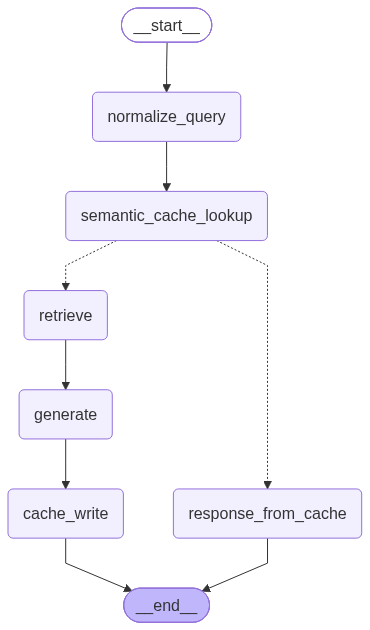

In [114]:
# ================== GRAPH WIRING ==================

graph = StateGraph(RAGState)

graph.add_node("normalize_query", normalize_query)
graph.add_node("semantic_cache_lookup", semantic_cache_lookup)
graph.add_node("response_from_cache", response_from_cache)
graph.add_node("retrieve", retrieve)
graph.add_node("generate", generate)
graph.add_node("cache_write", cache_write)

graph.set_entry_point("normalize_query")
graph.add_edge("normalize_query", "semantic_cache_lookup")

def _branch(state: RAGState) -> str:
    return "response_from_cache" if state.get("cache_hit") else "retrieve"

graph.add_conditional_edges(
    "semantic_cache_lookup",
    _branch,
    {
        "response_from_cache": "response_from_cache",
        "retrieve": "retrieve"
    }
)

graph.add_edge("response_from_cache", END)
graph.add_edge("retrieve", "generate")
graph.add_edge("generate", "cache_write")
graph.add_edge("cache_write", END)

memory = MemorySaver()
app = graph.compile(checkpointer=memory)
app



In [116]:
#================= DEMO =================
if __name__ == "__main__":
    # Demo code here
    thread_cfg = {"configurable": {"thread_id": "demo-user-1"}}

    q1 = "what is langGraph ?"
    out1 = app.invoke({"question": q1, "context_docs": [], "citations": []}, thread_cfg)

    print("Answer:", out1["answer"])
    print("Citations:", out1.get("citations"))
    print("Cache hit?", out1.get("cache_hit"))

Answer: LangGraph is a framework designed for building and deploying language models that can process and generate natural language. It emphasizes the integration of graph-based structures to enhance the capabilities of language models, allowing for more complex reasoning and understanding of relationships within the data. This framework aims to improve the efficiency and effectiveness of language processing tasks by leveraging the strengths of both language models and graph representations [doc-1].
Citations: ['(cache)']
Cache hit? True


In [119]:
q1 = "Explain about langGraph Agents?"
out1 = app.invoke({"question": q1, "context_docs": [], "citations": []}, thread_cfg)

print("Answer:", out1["answer"])
print("Citations:", out1.get("citations"))
print("Cache hit?", out1.get("cache_hit"))

Answer: LangGraph Agents are a framework designed to enhance the capabilities of language models by integrating them with graph-based knowledge representations. This approach allows agents to leverage structured information from graphs, enabling them to perform complex reasoning tasks and provide more accurate responses. By combining the strengths of language models with the relational data found in graphs, LangGraph Agents can better understand context and relationships, leading to improved performance in various applications such as question answering and information retrieval [doc-i].
Citations: ['(cache)']
Cache hit? True
